## CNN (Convolutional Neural Network)

In [3]:
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Flatten, Conv2D, MaxPooling2D, Dropout
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
x_train.shape

(60000, 28, 28)

CNN uses 3D values, hence we need to reshape our greyscaled 2D images to 3D

In [7]:
x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

# Normalize the data
x_train = x_train/255
x_test = x_test/255

In [8]:
model = Sequential([Input(shape=(28,28,1)),
                    Conv2D(32, (3,3), activation='relu', padding='same'),
                    MaxPooling2D((2,2)),
                    Conv2D(64, (3,3), activation='relu', padding='same'),
                    MaxPooling2D((2,2)),
                    Conv2D(128, (3,3), activation='relu', padding='same'),
                    MaxPooling2D((2,2)),
                    Flatten(),
                    Dense(64, activation='relu'),
                    Dense(32, activation='relu'),
                    Dense(10, activation='softmax')
                    ])

In [9]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(x_train, y_train, epochs=15, batch_size=32, verbose=1, validation_split=0.2)
test_loss, test_acc = model.evaluate(x_test, y_test)
print('Accuracy:', test_acc)
print('Loss:', test_loss)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - accuracy: 0.8089 - loss: 0.5228 - val_accuracy: 0.8699 - val_loss: 0.3554
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 64s 43ms/step - accuracy: 0.8835 - loss: 0.3167 - val_accuracy: 0.8889 - val_loss: 0.3089
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 65s 43ms/step - accuracy: 0.9034 - loss: 0.2627 - val_accuracy: 0.8900 - val_loss: 0.2999
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 77s 51ms/step - accuracy: 0.9178 - loss: 0.2262 - val_accuracy: 0.8932 - val_loss: 0.2909
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 77s 48ms/step - accuracy: 0.9274 - loss: 0.1983 - val_accuracy: 0.8996 - val_loss: 0.2770
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 79s 46ms/step - accuracy: 0.9361 - loss: 0.1746 - val_accuracy: 0.8953 - val_loss: 0.2857
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 73s 48ms/step - accuracy: 0.9433 - loss: 0.1525 - val_accuracy: 0.8962 - val_loss: 0.2998
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 78s 52ms/step - accuracy: 0.9496 -

In [16]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

y_pred_prob = model.predict(x_test)
y_pred = np.argmax(y_pred_prob, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step


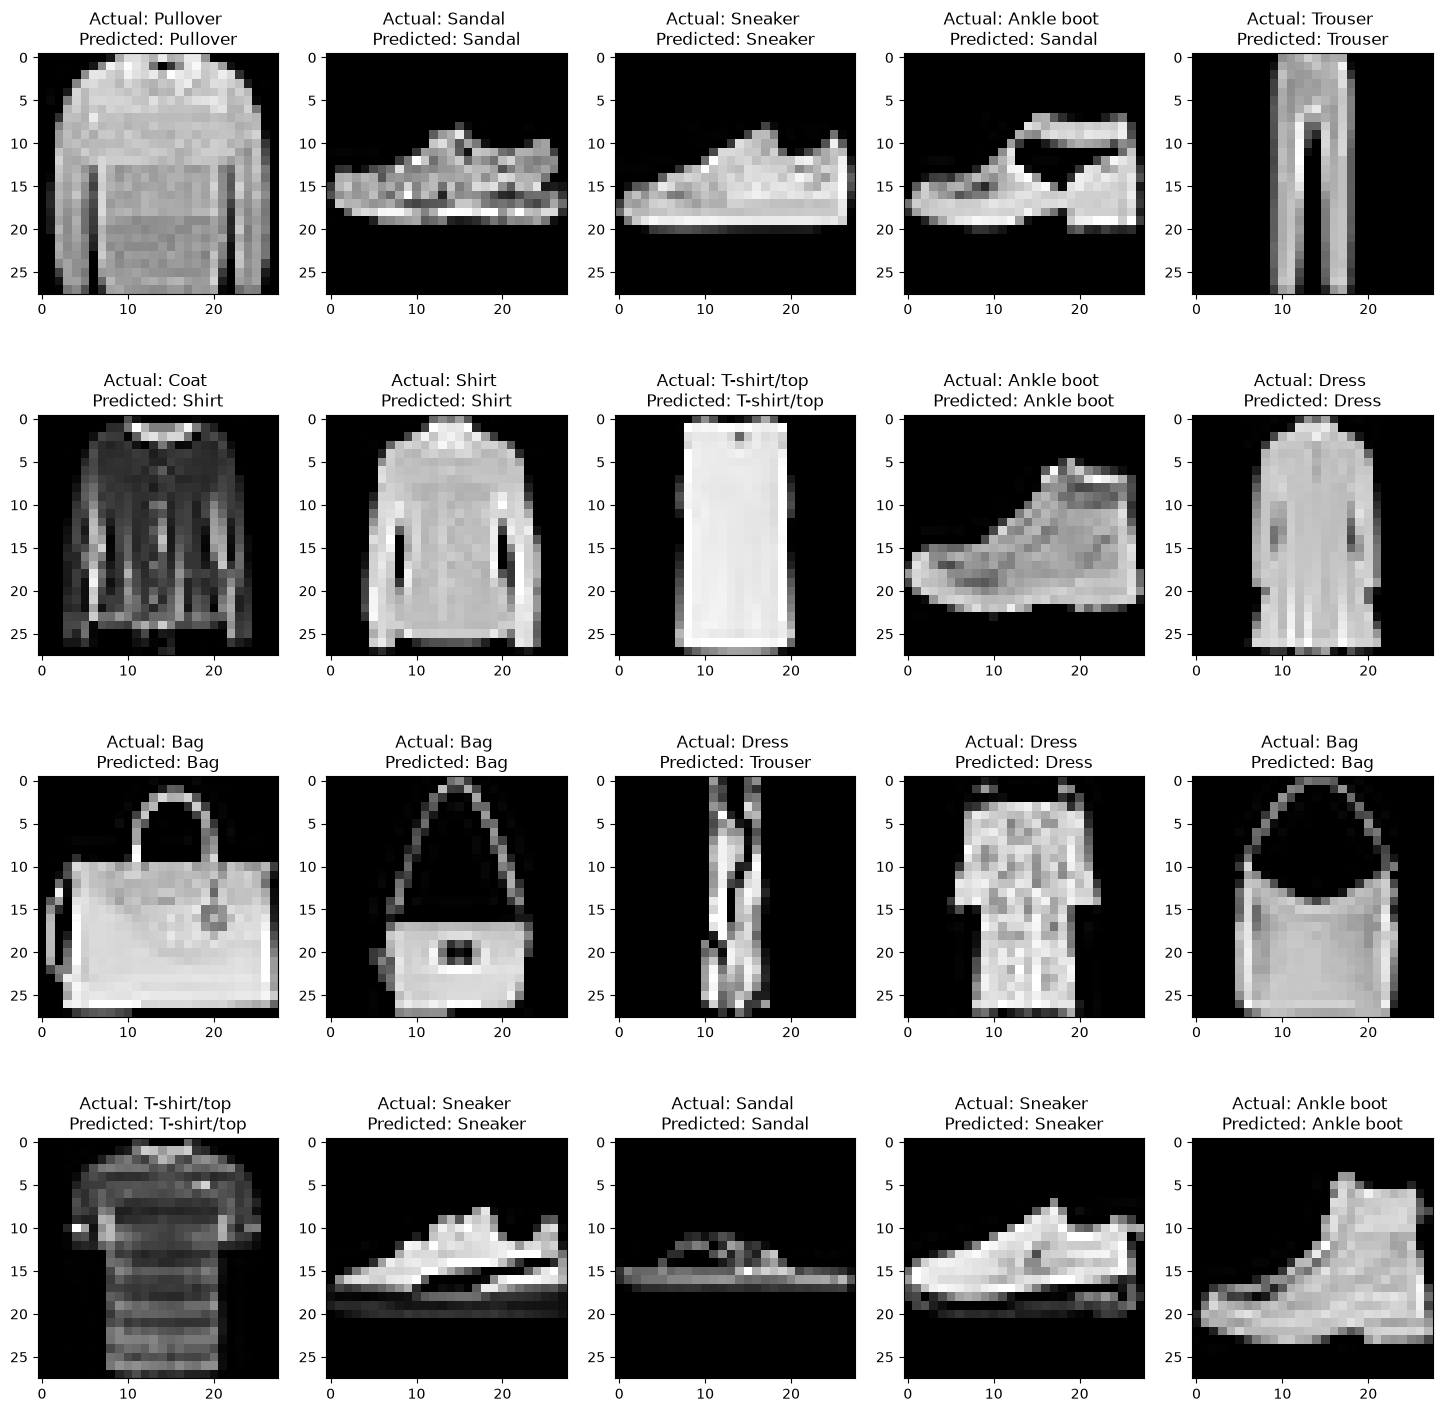

In [18]:

plt.figure(figsize=(18,18))
for i in range(20):
    plt.subplot(4,5,i+1)
    plt.imshow(x_test[i+20], cmap='gray')
    plt.title(f'Actual: {class_names[y_test[i+20]]} \nPredicted: {class_names[y_pred[i+20]]}')
plt.show()

### Colored Images Dataset

In [19]:
from tensorflow.keras.datasets import cifar10

In [21]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

  3555328/170498071 ━━━━━━━━━━━━━━━━━━━━ 1:09:38 25us/step

KeyboardInterrupt: 